# Silver Line Phase 1: did population and housing grow near the stations?
**Difference-in-differences, 2013 vs 2019 (ACS 5-year), Fairfax County, Virginia** (SDS-Fall26-Group 6)

* **Treated:** census tracts within 1 mile of a Phase 1 station (Wiehle-Reston East, Spring Hill, Greensboro, Tysons, McLean; opened July 2014), excluding tracts near stations that already existed.
* **Control:** tracts within 2 miles of the centre of five Fairfax job centres with no Metro service (rule fixed on 2013 data).
* **Outputs:** a study-area map, a DiD map (population and housing units), trend and estimate charts, and four statistical tables (shown below and downloaded as a zip).

**How to run:** `Runtime > Run all`. When the upload cell appears, select **all** your files at once:
1. ACS 5-year tables from data.census.gov, tract level: **B01003** (population) and **B25001** (housing units), for **2013** and **2019** (xlsx or csv; file names must contain e.g. `2013.B01003`, `2019.B25001`)
2. The 2014 Access Across America block shapefile zip (used only for tract shapes)
3. `Metro_Lines_Regional.zip` and `Metro_Stations_Regional_1.zip`
4. *Optional:* LODES `va_xwalk.csv.gz`, `va_wac_S000_JT00_2013.csv.gz`, `va_rac_S000_JT00_2013.csv.gz` (only used to choose the control places; without them the five places listed in the settings are used)

**Background maps:** free map tiles through `contextily` from providers that need **no API key** (Esri World Light Gray, then OpenStreetMap, then USGS Topo). Any provider that asks for a key is skipped automatically, and the provider's text credit is printed under each map (not a watermark). If no tiles can be downloaded, tract and county outlines from your own files are used instead. Set `BACKGROUND = "outlines"` in the settings cell to use only the outlines.

## 1. Install

In [ ]:
!pip -q install contextily pyogrio statsmodels openpyxl geopandas

## 2. Upload your files
Select all files at once. Zips are extracted automatically.

In [ ]:
import os
from google.colab import files
DATA_DIR = "data"
os.makedirs(DATA_DIR, exist_ok=True)
for name, content in files.upload().items():
    open(os.path.join(DATA_DIR, name), "wb").write(content)
print("Uploaded:", os.listdir(DATA_DIR))

Saving ACSDT5Y2013.B01003-2026-11-10T025336.xlsx to ACSDT5Y2013.B01003-2026-11-10T025336.xlsx
Saving ACSDT5Y2013.B01003-2026-11-10T025738.xlsx to ACSDT5Y2013.B01003-2026-11-10T025738.xlsx
Saving ACSDT5Y2013.B25001-2026-11-10T025530.xlsx to ACSDT5Y2013.B25001-2026-11-10T025530.xlsx
Saving ACSDT5Y2013.B25001-2026-11-10T025656.xlsx to ACSDT5Y2013.B25001-2026-11-10T025656.xlsx
Saving ACSDT5Y2019.B01003-2026-11-10T025346.xlsx to ACSDT5Y2019.B01003-2026-11-10T025346.xlsx
Saving ACSDT5Y2019.B01003-2026-11-10T025748.xlsx to ACSDT5Y2019.B01003-2026-11-10T025748.xlsx
Saving ACSDT5Y2019.B25001-2026-11-10T025503.xlsx to ACSDT5Y2019.B25001-2026-11-10T025503.xlsx
Saving ACSDT5Y2019.B25001-2026-11-10T025714.xlsx to ACSDT5Y2019.B25001-2026-11-10T025714.xlsx
Saving Metro_Lines_(Regional).zip to Metro_Lines_(Regional).zip
Saving Metro_Stations_(Regional) (1).zip to Metro_Stations_(Regional) (1).zip
Saving WA_transit_accessibility_data_2014_geopackage.zip to WA_transit_accessibility_data_2014_geopackage.

## 3. Imports and settings
Edit `BACKGROUND`, the control-place centres or the distances here if you want to change the design.

In [ ]:
import os, re, sys, glob, zipfile, warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import statsmodels.formula.api as smf
import matplotlib
if "google.colab" not in sys.modules and not os.environ.get("DISPLAY"):
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from shapely.ops import unary_union
warnings.filterwarnings("ignore")

DATA_DIR   = os.environ.get("DATA_DIR", "data")        # folder with your files (Colab: files are uploaded here)
OUT_DIR    = os.environ.get("OUT_DIR", "outputs")
BACKGROUND = os.environ.get("BACKGROUND", "tiles")     # "tiles" or "outlines"
TILE_SOURCES = ["Esri.WorldGrayCanvas", "OpenStreetMap.Mapnik", "USGS.USTopo"]   # keyless providers, tried in order
STUDY_FIPS  = "51059"                                  # Fairfax County, VA
TREATED_MILES, CONTROL_RADIUS_MILES, MIN_CONTROL_DISTANCE_MILES, N_CONTROL_PLACES = 1.0, 2.0, 3.0, 5
NEAR_METRO_EXCLUDE_MILES = 1.5                         # control tracts must not come within this distance of any Metro station
PHASE1 = ["Wiehle-Reston East", "Spring Hill", "Greensboro", "Tysons", "McLean"]
PHASE2 = ["Reston Town Center", "Herndon", "Innovation Center", "Washington Dulles International Airport",
          "Loudoun Gateway", "Ashburn"]
# Used if the LODES files are not supplied (these are the five places the selection rule picked: longitude, latitude)
CONTROL_CENTERS = {"Fair Oaks": (-77.35884, 38.86108), "Chantilly": (-77.44256, 38.88661),
                   "Fair Lakes": (-77.38697, 38.85812), "Braddock": (-77.35531, 38.83597),
                   "George Mason": (-77.31130, 38.83279)}
MI = 1609.344
BLUE, GRAY, PINK = "#08519c", "#7f7f7f", "#e6007e"
COUNTY_FIPS = {"Fairfax County": "51059", "Loudoun County": "51107", "Arlington County": "51013",
               "Prince William County": "51153", "Alexandria city": "51510", "Falls Church city": "51610",
               "Fairfax city": "51600", "Manassas city": "51683", "Manassas Park city": "51685",
               "District of Columbia": "11001"}
os.makedirs(OUT_DIR, exist_ok=True)

## 4. Find and read the input files

In [ ]:
EXTRACT = os.path.join(DATA_DIR, "_unzipped")
for z in glob.glob(os.path.join(DATA_DIR, "**", "*.zip"), recursive=True):
    if "_unzipped" in z or "__MACOSX" in z:
        continue
    try:
        zipfile.ZipFile(z).extractall(os.path.join(EXTRACT, os.path.splitext(os.path.basename(z))[0]))
    except Exception as e:
        print("could not unzip", z, e)

def find_files(ext, *must):
    out = []
    for p in glob.glob(os.path.join(DATA_DIR, "**", "*"), recursive=True):
        n = os.path.basename(p)
        if "__MACOSX" in p or n.startswith(".") or not n.lower().endswith(ext):
            continue
        if all(m.lower() in p.lower() for m in must):
            out.append(p)
    return sorted(out)

def find_file(ext, *must, required=True):
    f = find_files(ext, *must)
    if not f:
        if required:
            raise FileNotFoundError(f"No '{ext}' file containing {must} found under {DATA_DIR}")
        return None
    return f[0]

## 5. ACS tables (population and housing units, 2013 and 2019)

In [ ]:
def read_acs(path):
    """Return {tract GEOID: estimate} from a data.census.gov download (xlsx 'Data' sheet or csv)."""
    if path.lower().endswith(".xlsx"):
        d = pd.read_excel(path, sheet_name="Data", header=None, dtype=str)
        pairs = [(d.iloc[0, j], d.iloc[2, j]) for j in range(1, d.shape[1])
                 if isinstance(d.iloc[0, j], str) and str(d.iloc[1, j]).strip().lower().startswith("estimate")]
    else:
        d = pd.read_csv(path, dtype=str); d.columns = [c.strip() for c in d.columns]
        pairs = [(c, d.iloc[0][c]) for c in d.columns[1:] if c.endswith("!!Estimate")]
    out = {}
    for name, val in pairs:
        m = re.match(r"Census Tract ([\d.]+)[,;] (.+?)[,;] (Virginia|District of Columbia)", str(name))
        if not m or m.group(2) not in COUNTY_FIPS:
            continue
        try:
            out[COUNTY_FIPS[m.group(2)] + f"{int(round(float(m.group(1)) * 100)):06d}"] = float(str(val).replace(",", ""))
        except ValueError:
            pass
    return out

def load_acs(table, year):
    files = [f for ext in (".xlsx", ".csv") for f in find_files(ext, f"{year}.{table}")]
    if not files:
        raise FileNotFoundError(f"No ACS file for {table} {year} (name must contain '{year}.{table}')")
    d = {}
    for f in files:
        d.update(read_acs(f))
    return pd.Series({k: v for k, v in d.items() if k.startswith(STUDY_FIPS)})

acs = pd.DataFrame({"pop13": load_acs("B01003", 2013), "pop19": load_acs("B01003", 2019),
                    "hu13": load_acs("B25001", 2013), "hu19": load_acs("B25001", 2019)}).dropna()
acs = acs[(acs.pop13 > 0) & (acs.hu13 > 0)]
print(f"ACS tracts with all four values: {len(acs)}")

ACS tracts with all four values: 255


## 6. Tract shapes, stations and the Silver Line

In [ ]:
blocks_path = find_file(".shp", "_tr_2014")
blocks = gpd.read_file(blocks_path, columns=["geoid"])
blocks = blocks[blocks.geoid.str[:5] == STUDY_FIPS].to_crs(32618)
tracts = blocks.assign(t=blocks.geoid.str[:11]).dissolve("t")
T = tracts.join(acs, how="inner")
print(f"Tracts joined to geometry: {len(T)}")

stations = gpd.read_file(find_file(".shp", "station")).to_crs(32618)
lines = gpd.read_file(find_file(".shp", "line")).to_crs(32618)
silver = lines[lines.NAME.str.lower() == "silver"]
s1 = stations[stations.NAME.isin(PHASE1)].drop_duplicates("NAME").set_index("NAME")
s2 = stations[stations.NAME.isin(PHASE2)].drop_duplicates("NAME")
existing = stations[~stations.NAME.isin(PHASE1 + PHASE2)]
buf = lambda g, mi: unary_union(g.geometry.buffer(mi * MI).values)
g1 = buf(s1.reset_index(), TREATED_MILES)
g_existing = buf(existing, TREATED_MILES)
g_any = buf(stations, NEAR_METRO_EXCLUDE_MILES)

Tracts joined to geometry: 255


## 7. Control places
Rule (2013 data only): among Fairfax places whose centre is at least 3 miles from any Metro station, take the five with the most jobs within 2 miles of the centre. This step only uses LODES if the files were uploaded; it does not use any growth numbers.

In [ ]:
def select_control_places():
    """Rule (2013 data only): among Fairfax places whose centre is >= 3 miles from any Metro station, take the
    five with the most jobs within 2 miles of the centre. Needs the LODES xwalk, WAC 2013 and RAC 2013."""
    xw, w13p, r13p = find_file(".gz", "xwalk", required=False), find_file(".gz", "wac", "2013", required=False), find_file(".gz", "rac", "2013", required=False)
    if not (xw and w13p and r13p):
        print("LODES files not found -> using CONTROL_CENTERS from the settings.")
        return None
    from shapely.strtree import STRtree
    x = pd.read_csv(xw, dtype=str, usecols=["tabblk2020", "cty", "stplcname", "blklatdd", "blklondd"]).set_index("tabblk2020")
    x = x[x.cty.isin(["51059", "51600"])].copy()
    w13 = pd.read_csv(w13p, usecols=["w_geocode", "C000"], dtype={"w_geocode": str}).set_index("w_geocode").C000
    r13 = pd.read_csv(r13p, usecols=["h_geocode", "C000"], dtype={"h_geocode": str}).set_index("h_geocode").C000
    x["jobs"], x["res"] = w13.reindex(x.index).fillna(0), r13.reindex(x.index).fillna(0)
    x["lat"], x["lon"] = x.blklatdd.astype(float), x.blklondd.astype(float)
    pts = gpd.GeoSeries(gpd.points_from_xy(x.lon, x.lat), crs=4326).to_crs(32618)
    tree, jobs = STRtree(pts.values), x.jobs.values
    any_station = unary_union(stations.geometry.values)
    rows = []
    for place, g in x[x.stplcname.notna()].groupby("stplcname"):
        wt = g.jobs + g.res + 1
        c = gpd.GeoSeries(gpd.points_from_xy([np.average(g.lon, weights=wt)], [np.average(g.lat, weights=wt)]), crs=4326).to_crs(32618).iloc[0]
        circle = c.buffer(CONTROL_RADIUS_MILES * MI)
        ntr = int((T.intersects(circle) & ~T.intersects(g_any)).sum())
        rows.append((place, c.distance(any_station) / MI, ntr, jobs[tree.query(circle, predicate="intersects")].sum(), c))
    P = pd.DataFrame(rows, columns=["place", "d_metro", "tracts", "jobs13_2mi", "geometry"])
    P = P[(P.d_metro >= MIN_CONTROL_DISTANCE_MILES) & (P.tracts >= 5)].sort_values("jobs13_2mi", ascending=False).head(N_CONTROL_PLACES)
    print("Control places chosen by the 2013 rule:\n", P[["place", "d_metro", "jobs13_2mi", "tracts"]].round(1).to_string(index=False))
    return {r.place.replace(" CDP, VA", "").replace(" city, VA", ""): r.geometry for r in P.itertuples()}

centres = select_control_places()
if centres is None:
    centres = {k: gpd.GeoSeries(gpd.points_from_xy([v[0]], [v[1]]), crs=4326).to_crs(32618).iloc[0] for k, v in CONTROL_CENTERS.items()}
circles = {k: v.buffer(CONTROL_RADIUS_MILES * MI) for k, v in centres.items()}

LODES files not found -> using CONTROL_CENTERS from the settings.


## 8. Treated and control groups, growth rates

In [ ]:
T["group"] = "other"
T.loc[T.intersects(g1) & ~T.intersects(g_existing), "group"] = "Phase 1"
ctl_ids = set()
place_tracts = {}
for k, c in circles.items():
    ids = T[T.intersects(c) & ~T.intersects(g_any) & (T.group != "Phase 1")].index
    place_tracts[k] = ids; ctl_ids |= set(ids)
T.loc[T.index.isin(ctl_ids), "group"] = "Control"
for v in ("pop", "hu"):
    T[v + "_pct"] = 100 * (T[v + "19"] / T[v + "13"] - 1)
P, K = T[T.group == "Phase 1"].copy(), T[T.group == "Control"].copy()
P["treat"], K["treat"] = 1, 0
A = pd.concat([P, K])
print(f"Treated tracts: {len(P)}   Control tracts: {len(K)}")
mu = {v: K[v + "_pct"].mean() for v in ("pop", "hu")}
for v in ("pop", "hu"):
    P[v + "_did"] = P[v + "_pct"] - mu[v]
P["station"] = [s1.geometry.distance(g.centroid).idxmin() for g in P.geometry]
OUTCOMES = (("pop", "Population"), ("hu", "Housing units"))

Treated tracts: 21   Control tracts: 36


## 9. Statistical tables and difference-in-differences estimates

In [ ]:
rows = []
for g, lab in ((P, "Phase 1 station tracts"), (K, "Control place tracts")):
    for v, vl in OUTCOMES:
        for y in ("13", "19"):
            x = g[v + y]
            rows.append({"Outcome": vl, "Group": lab, "Year": 2000 + int(y), "Tracts": len(x), "Mean per tract": x.mean(),
                         "Median": x.median(), "SD": x.std(), "Min": x.min(), "Max": x.max(), "Total": x.sum()})
tab1 = pd.DataFrame(rows).sort_values(["Outcome", "Group", "Year"], ascending=[False, False, True])

def did(df, v, kind="log"):
    """Two-period DiD with tract fixed effects == regression of each tract's change on the treatment dummy."""
    d = df[df[v + "13"] > 0].copy()
    d["dy"] = np.log(d[v + "19"] / d[v + "13"]) if kind == "log" else d[v + "19"] - d[v + "13"]
    m = smf.ols("dy~treat", d).fit(cov_type="HC1")
    b, (lo, hi), p = m.params["treat"], m.conf_int().loc["treat"], m.pvalues["treat"]
    return (100 * (np.exp(b) - 1), 100 * (np.exp(lo) - 1), 100 * (np.exp(hi) - 1), p) if kind == "log" else (b, lo, hi, p)

rows = []
for v, vl in OUTCOMES:
    top2_all = (A[v + "19"] / A[v + "13"]).sort_values(ascending=False).index[:2]
    top2_p1 = (P[v + "19"] / P[v + "13"]).sort_values(ascending=False).index[:2]
    specs = [("DiD, % growth above control places (log, tract fixed effects)", A, "log", "%"),
             (f"DiD, extra {'people' if v == 'pop' else 'housing units'} per tract (levels)", A, "lvl", ""),
             ("DiD (log) without the 2 fastest-growing tracts overall", A.drop(top2_all), "log", "%"),
             ("DiD (log) without the 2 fastest-growing Phase 1 tracts", A.drop(top2_p1), "log", "%")]
    for name, df, kind, unit in specs:
        e, lo, hi, p = did(df, v, kind)
        rows.append({"Outcome": vl, "Specification": name, "Estimate": e, "CI low": lo, "CI high": hi, "p-value": p, "Tracts": len(df)})
tab2 = pd.DataFrame(rows)

rows = []
for stn, g in list(P.groupby("station")) + [("All Phase 1 tracts", P)]:
    r = {"Station (nearest)": stn, "Tracts": len(g)}
    for v, vl in OUTCOMES:
        e, lo, hi, p = did(pd.concat([g, K]), v)
        r.update({f"{vl}: growth %": 100 * (g[v + "19"].sum() / g[v + "13"].sum() - 1), f"{vl}: DiD %": e,
                  f"{vl}: 95% CI": f"{lo:.1f} to {hi:.1f}", f"{vl}: p": p})
    rows.append(r)
tab3 = pd.DataFrame(rows)

rows = []
for k, ids in place_tracts.items():
    q = T.loc[ids]
    rows.append({"Control place": k, "Tracts (2-mile circle)": len(q), "Population 2013": q.pop13.sum(), "Population 2019": q.pop19.sum(),
                 "Population growth %": 100 * (q.pop19.sum() / q.pop13.sum() - 1), "Housing units 2013": q.hu13.sum(),
                 "Housing units 2019": q.hu19.sum(), "Housing growth %": 100 * (q.hu19.sum() / q.hu13.sum() - 1)})
tab4 = pd.DataFrame(rows)

for name, t in (("table1_descriptives", tab1), ("table2_did_estimates", tab2), ("table3_station_did", tab3), ("table4_control_places", tab4)):
    t.round(3).to_csv(os.path.join(OUT_DIR, name + ".csv"), index=False)
with pd.ExcelWriter(os.path.join(OUT_DIR, "statistical_tables.xlsx")) as xw:
    for name, t in (("1 Descriptives", tab1), ("2 DiD estimates", tab2), ("3 By station", tab3), ("4 Control places", tab4)):
        t.round(3).to_excel(xw, sheet_name=name, index=False)
pd.set_option("display.width", 250, "display.max_columns", 30)
for name, t in (("TABLE 1: descriptives", tab1), ("TABLE 2: DiD estimates", tab2), ("TABLE 3: by station", tab3), ("TABLE 4: control places", tab4)):
    print("\n" + name); print(t.round(2).to_string(index=False))


TABLE 1: descriptives
      Outcome                  Group  Year  Tracts  Mean per tract  Median      SD    Min    Max    Total
   Population Phase 1 station tracts  2013      21         3889.95  3512.0 1252.81 2376.0 6837.0  81689.0
   Population Phase 1 station tracts  2019      21         4190.71  4298.0 1400.30 2235.0 7053.0  88005.0
   Population   Control place tracts  2013      36         4857.47  4759.5 1512.14 2141.0 7681.0 174869.0
   Population   Control place tracts  2019      36         5040.28  4934.0 1624.28 2557.0 7742.0 181450.0
Housing units Phase 1 station tracts  2013      21         1687.90  1781.0  582.17  773.0 2428.0  35446.0
Housing units Phase 1 station tracts  2019      21         1801.48  1749.0  696.38  763.0 3348.0  37831.0
Housing units   Control place tracts  2013      36         1704.28  1602.5  602.07  760.0 3378.0  61354.0
Housing units   Control place tracts  2019      36         1706.50  1648.5  615.07  778.0 3286.0  61434.0

TABLE 2: DiD estimates

## 10. Map helpers (open-source background)

In [ ]:
Tm = T.to_crs(3857)
P_m, K_m = Tm.loc[P.index], Tm.loc[K.index]
s1_m, st_m, silver_m = s1.to_crs(3857), stations.to_crs(3857), silver.to_crs(3857)
county_m = gpd.GeoSeries([Tm.geometry.union_all() if hasattr(Tm.geometry, "union_all") else Tm.unary_union], crs=3857)
to_m = lambda g: gpd.GeoSeries([g], crs=32618).to_crs(3857).iloc[0]
rings_m = {r: to_m(buf(s1.reset_index(), r)) for r in (0.5, 1.0)}
circles_m = {k: to_m(c) for k, c in circles.items()}
centres_m = {k: to_m(c) for k, c in centres.items()}
TILES_OK = {"state": BACKGROUND == "tiles", "credit": ""}

def _provider(name):
    import contextily as cx
    src = cx.providers
    for part in name.split("."):
        src = src[part]
    return src

def add_background(ax, xlim, ylim):
    """Open-source background: keyless tiles if reachable, otherwise tract and county outlines."""
    ax.set_xlim(xlim); ax.set_ylim(ylim); ax.set_aspect("equal")
    if TILES_OK["state"]:
        try:
            import contextily as cx
        except ImportError:
            cx = None; TILES_OK["state"] = False
        for name in (TILE_SOURCES if cx else []):
            try:
                src = _provider(name)
                if hasattr(src, "requires_token") and src.requires_token():
                    print(f"Skipping {name}: needs an API key"); continue
                cx.add_basemap(ax, crs="EPSG:3857", source=src, attribution=False, zoom="auto")
                ax.set_xlim(xlim); ax.set_ylim(ylim)
                TILES_OK["credit"] = "Basemap: " + re.sub(r"<[^>]+>|&copy;", "", str(src.get("attribution", name))).replace("  ", " ").strip()
                return
            except Exception as e:
                print(f"Tiles from {name} unavailable ({type(e).__name__}); trying the next source.")
        TILES_OK["state"] = False
        print("No keyless tiles could be downloaded -> using tract and county outlines instead.")
    ax.set_facecolor("#f3f3f1")
    Tm.boundary.plot(ax=ax, color="#bdbdbd", lw=.4, zorder=1)
    gpd.GeoSeries(county_m.boundary).plot(ax=ax, color="#7a7a7a", lw=1.0, zorder=1)

def credit(fig, extra=""):
    txt = (TILES_OK["credit"] if TILES_OK["state"] else "Background: census tract outlines (2010) from the Access Across America block file") + extra
    fig.text(0.5, 0.005, txt, ha="center", va="bottom", fontsize=8, color="#555555")

def pad_bounds(b, f=0.06, ratio=None):
    w, h = b[2] - b[0], b[3] - b[1]; xl, xr, yb, yt = b[0] - w * f, b[2] + w * f, b[1] - h * f, b[3] + h * f
    if ratio:
        cx_, cy_, W = (xl + xr) / 2, (yb + yt) / 2, xr - xl
        H = W / ratio
        if (yt - yb) > H:
            H = yt - yb; W = H * ratio
        xl, xr, yb, yt = cx_ - W / 2, cx_ + W / 2, cy_ - H / 2, cy_ + H / 2
    return (xl, xr), (yb, yt)

def halo(): return [pe.withStroke(linewidth=3, foreground="white")]

def draw_stations(ax, labels=True, offsets=None):
    silver_m.plot(ax=ax, color=PINK, lw=3.2, zorder=6)
    for r, ls in ((0.5, "-"), (1.0, "--")):
        gpd.GeoSeries([rings_m[r]], crs=3857).boundary.plot(ax=ax, color="k", lw=1.3, ls=ls, zorder=7)
    s1_m.plot(ax=ax, color="white", edgecolor=PINK, linewidth=2.4, markersize=55, zorder=8)
    if labels:
        offsets = offsets or {}
        for n, r in s1_m.iterrows():
            ax.annotate(n, (r.geometry.x, r.geometry.y), xytext=offsets.get(n, (0, 12)), textcoords="offset points", ha="center",
                        fontsize=9, fontweight="bold", zorder=10, path_effects=halo())

## 11. Figure 1: study area

In [ ]:
fig, ax = plt.subplots(figsize=(13, 8.5))
xl, yl = pad_bounds(unary_union([P_m.geometry.union_all() if hasattr(P_m.geometry, "union_all") else P_m.unary_union, *circles_m.values()]).bounds, 0.05, 1.5)
add_background(ax, xl, yl)
Tm.boundary.plot(ax=ax, color="#9a9a9a", lw=.35, zorder=2)
K_m.plot(ax=ax, color="#6b7a99", alpha=.40, edgecolor="#4a5875", linewidth=.6, zorder=3)
P_m.plot(ax=ax, color=PINK, alpha=.32, edgecolor=PINK, linewidth=.9, zorder=3)
for k, c in circles_m.items():
    gpd.GeoSeries([c], crs=3857).boundary.plot(ax=ax, color="#222", lw=1.4, ls="--", zorder=7)
    ax.plot(centres_m[k].x, centres_m[k].y, "k*", ms=11, zorder=9)
    ax.annotate(k, (centres_m[k].x, centres_m[k].y), xytext=(0, 12), textcoords="offset points", ha="center", fontsize=9, fontweight="bold", zorder=10, path_effects=halo())
draw_stations(ax, offsets={"Wiehle-Reston East": (0, -20), "Spring Hill": (-48, 14), "Greensboro": (-55, -8), "Tysons": (0, -26), "McLean": (28, 16)})
ax.set_xlim(xl); ax.set_ylim(yl); ax.axis("off")
ax.legend(handles=[Patch(fc=PINK, alpha=.4, ec=PINK, label=f"Phase 1 station tracts (n={len(P)})"),
                   Patch(fc="#6b7a99", alpha=.5, ec="#4a5875", label=f"Control place tracts (n={len(K)})"),
                   Line2D([], [], color=PINK, lw=3, label="Silver Line"),
                   Line2D([], [], marker="o", mfc="w", mec=PINK, mew=2.2, ls="", label="Phase 1 stations (opened Jul 2014)"),
                   Line2D([], [], color="k", lw=1.3, label="0.5 mile / 1 mile (dashed) from Phase 1 stations"),
                   Line2D([], [], color="#222", lw=1.4, ls="--", marker="*", mfc="k", label="2-mile circle around control place centre")],
          loc="lower left", fontsize=9, frameon=True, framealpha=.92)
ax.set_title("Study area: Phase 1 station tracts and no-Metro control places, Fairfax County", fontsize=13, fontweight="bold", loc="left")
credit(fig); fig.tight_layout(rect=(0, 0.02, 1, 1)); fig.savefig(os.path.join(OUT_DIR, "fig1_study_area_map.png"), dpi=140, bbox_inches="tight"); plt.close(fig)

## 12. Figure 2: difference-in-differences map

In [ ]:
BR = [-np.inf, -25, -10, -3, 3, 10, 25, np.inf]
COL = ["#4d4d4d", "#969696", "#d9d9d9", "#ffffff", "#d6e8f7", "#6baed6", "#08519c"]
LAB = ["below -25", "-25 to -10", "-10 to -3", "-3 to +3 (no difference)", "+3 to +10", "+10 to +25", "above +25"]
xl, yl = pad_bounds(P_m.total_bounds, 0.04, 1.55)
fig, axs = plt.subplots(1, 2, figsize=(21, 8.4))
for ax, (v, vl) in zip(axs, OUTCOMES):
    add_background(ax, xl, yl)
    cls = pd.cut(P[v + "_did"], BR, labels=False)
    for i, c in enumerate(COL):
        q = P_m[(cls == i).values]
        if len(q): q.plot(ax=ax, color=c, alpha=.82, edgecolor="#444", linewidth=.8, zorder=3)
    draw_stations(ax, offsets={"Wiehle-Reston East": (0, -22), "Spring Hill": (-55, 14), "Greensboro": (-62, -6), "Tysons": (4, -26), "McLean": (30, 16)})
    for idx, r in P_m.iterrows():
        pt = r.geometry.representative_point()
        if xl[0] < pt.x < xl[1] and yl[0] < pt.y < yl[1]:
            ax.annotate(f"{P.loc[idx, v + '_did']:+.0f}", (pt.x, pt.y), ha="center", va="center", fontsize=8, zorder=9, path_effects=halo())
    ax.set_xlim(xl); ax.set_ylim(yl); ax.axis("off")
    ax.set_title(f"{vl}: tract growth minus control-place average ({mu[v]:+.1f}%)", fontsize=13, fontweight="bold")
    ax.legend(handles=[Patch(fc=c, ec="#777", label=l) for c, l in zip(COL, LAB)], loc="upper center", bbox_to_anchor=(.5, -.01), ncol=4, frameon=False,
              fontsize=9, title="Percentage points above (blue) or below (gray) the control places; numbers = points per tract")
fig.suptitle("Difference-in-differences in map form: Phase 1 station tracts vs. control places, 2013 to 2019", fontsize=15, fontweight="bold", y=.995)
credit(fig); fig.tight_layout(rect=(0, 0.02, 1, 0.98)); fig.savefig(os.path.join(OUT_DIR, "fig2_did_map_pop_housing.png"), dpi=130, bbox_inches="tight"); plt.close(fig)

## 13. Figure 3: trends and DiD estimates

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5.2), gridspec_kw=dict(width_ratios=[1, 1, 1.25]))
for a, (v, vl) in zip(ax[:2], OUTCOMES):
    for g, lab, c in ((P, "Phase 1 station tracts", BLUE), (K, "Control place tracts", GRAY)):
        y1 = 100 * g[v + "19"].sum() / g[v + "13"].sum()
        a.plot([2013, 2019], [100, y1], "o-", color=c, lw=2.5, ms=8, label=lab)
        a.annotate(f"{y1:.1f}", (2019, y1), xytext=(8, -3), textcoords="offset points", fontsize=10, color=c, fontweight="bold")
    a.set_xticks([2013, 2019]); a.set_xlim(2012.6, 2019.8); a.set_title(f"{vl} (2013 = 100)", loc="left", fontweight="bold")
    a.spines[["top", "right"]].set_visible(False); a.grid(axis="y", alpha=.25); a.legend(frameon=False, fontsize=9, loc="upper left")
a = ax[2]; Z = tab2[tab2.Specification.str.startswith("DiD, %") | tab2.Specification.str.contains("without")]; labs = []
for i, (_, r) in enumerate(Z.iterrows()):
    c = BLUE if r.Outcome == "Housing units" else "#d98a1f"
    a.plot([r["CI low"], r["CI high"]], [i, i], color=c, lw=2.5); a.plot(r.Estimate, i, "o", color=c, ms=8)
    a.annotate(f"{r.Estimate:+.1f}%  (p={r['p-value']:.2f})", (r["CI high"], i), xytext=(6, -3), textcoords="offset points", fontsize=8.5)
    short = "all tracts" if r.Specification.startswith("DiD, %") else ("drop 2 fastest (any)" if "overall" in r.Specification else "drop 2 fastest Phase 1")
    labs.append(f"{r.Outcome}: {short}")
a.axvline(0, color="k", lw=.9); a.set_yticks(range(len(Z))); a.set_yticklabels(labs, fontsize=9); a.invert_yaxis()
a.set_xlabel("DiD estimate: growth above control places (%, 95% CI)"); a.set_title("Difference-in-differences estimates", loc="left", fontweight="bold")
a.spines[["top", "right"]].set_visible(False); a.grid(axis="x", alpha=.25); a.set_xlim(a.get_xlim()[0], a.get_xlim()[1] + 9)
fig.text(0.01, 0.0, "Only two time points (2013, 2019): lines join the two points and parallel pre-trends cannot be tested.", fontsize=8, color="#555")
fig.tight_layout(rect=(0, 0.02, 1, 1)); fig.savefig(os.path.join(OUT_DIR, "fig3_trends_and_did.png"), dpi=130, bbox_inches="tight"); plt.close(fig)

## 14. Statistical tables as one image

In [ ]:
def fmt(df):
    out = df.copy()
    for c in out.columns:
        if pd.api.types.is_float_dtype(out[c]):
            out[c] = out[c].map(lambda x: f"{x:,.3f}" if "p" in c.lower().split()[-1:] or c in ("p-value",) or c.endswith(": p") else f"{x:,.1f}")
        elif pd.api.types.is_integer_dtype(out[c]) and c != "Year":
            out[c] = out[c].map(lambda x: f"{x:,}")
    return out
parts = [("Table 1. Descriptive statistics by tract (ACS 5-year, Fairfax County)", fmt(tab1)),
         ("Table 2. Difference-in-differences estimates, Phase 1 tracts vs. control places (growth above control; 95% CI; HC1 robust SE)", fmt(tab2.assign(Estimate=tab2.Estimate))),
         ("Table 3. DiD by nearest Phase 1 station", fmt(tab3)),
         ("Table 4. Control places (tracts within 2 miles of the place centre)", fmt(tab4))]
heights = [len(d) + 3 for _, d in parts]
fig, axs = plt.subplots(len(parts), 1, figsize=(17, 0.36 * sum(heights) + 1), gridspec_kw=dict(height_ratios=heights))
for a, (title, d) in zip(axs, parts):
    a.axis("off"); a.set_title(title, loc="left", fontsize=11, fontweight="bold")
    tb = a.table(cellText=d.values, colLabels=list(d.columns), loc="upper center", cellLoc="center")
    tb.auto_set_font_size(False); tb.set_fontsize(8.2); tb.auto_set_column_width(list(range(len(d.columns)))); tb.scale(1, 1.35)
    for (r, c), cell in tb.get_celld().items():
        cell.set_edgecolor("#cccccc")
        if r == 0: cell.set_facecolor("#e8eef7"); cell.set_text_props(fontweight="bold")
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "statistical_tables.png"), dpi=150, bbox_inches="tight"); plt.close(fig)

## 15. View the results

fig1_study_area_map.png


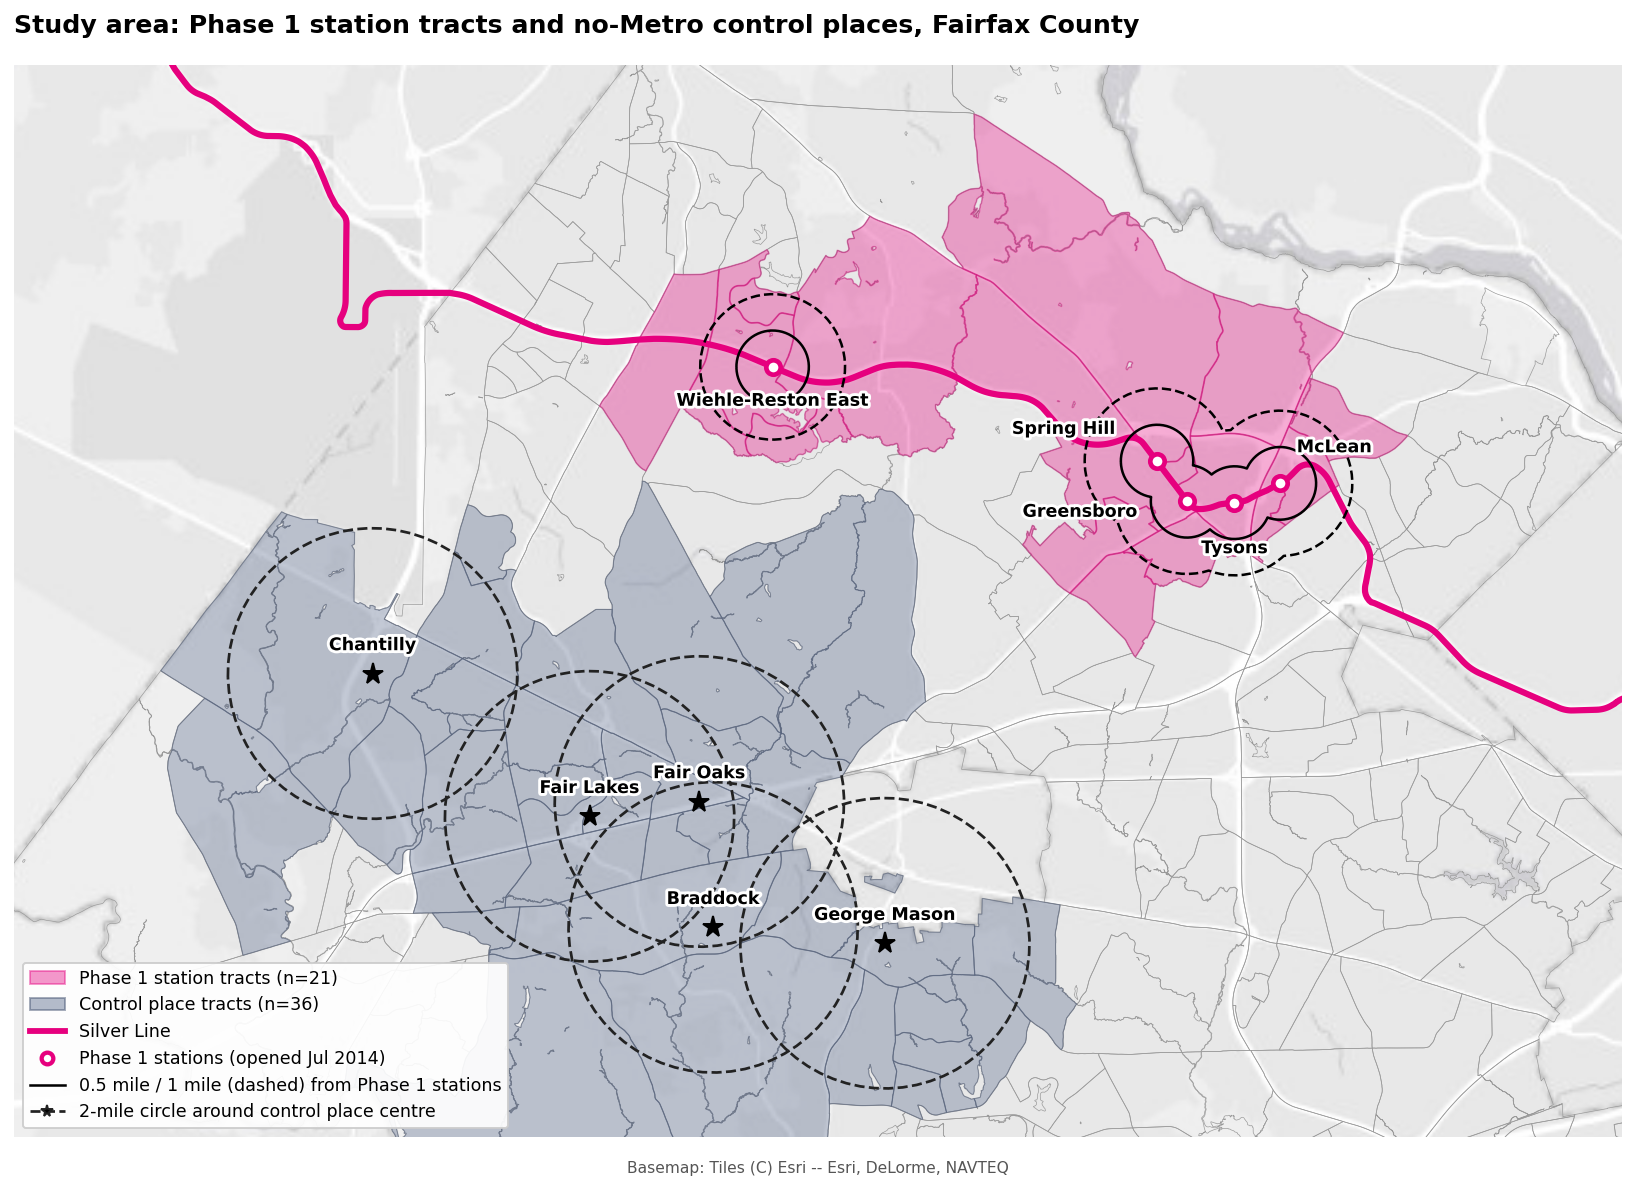

fig2_did_map_pop_housing.png


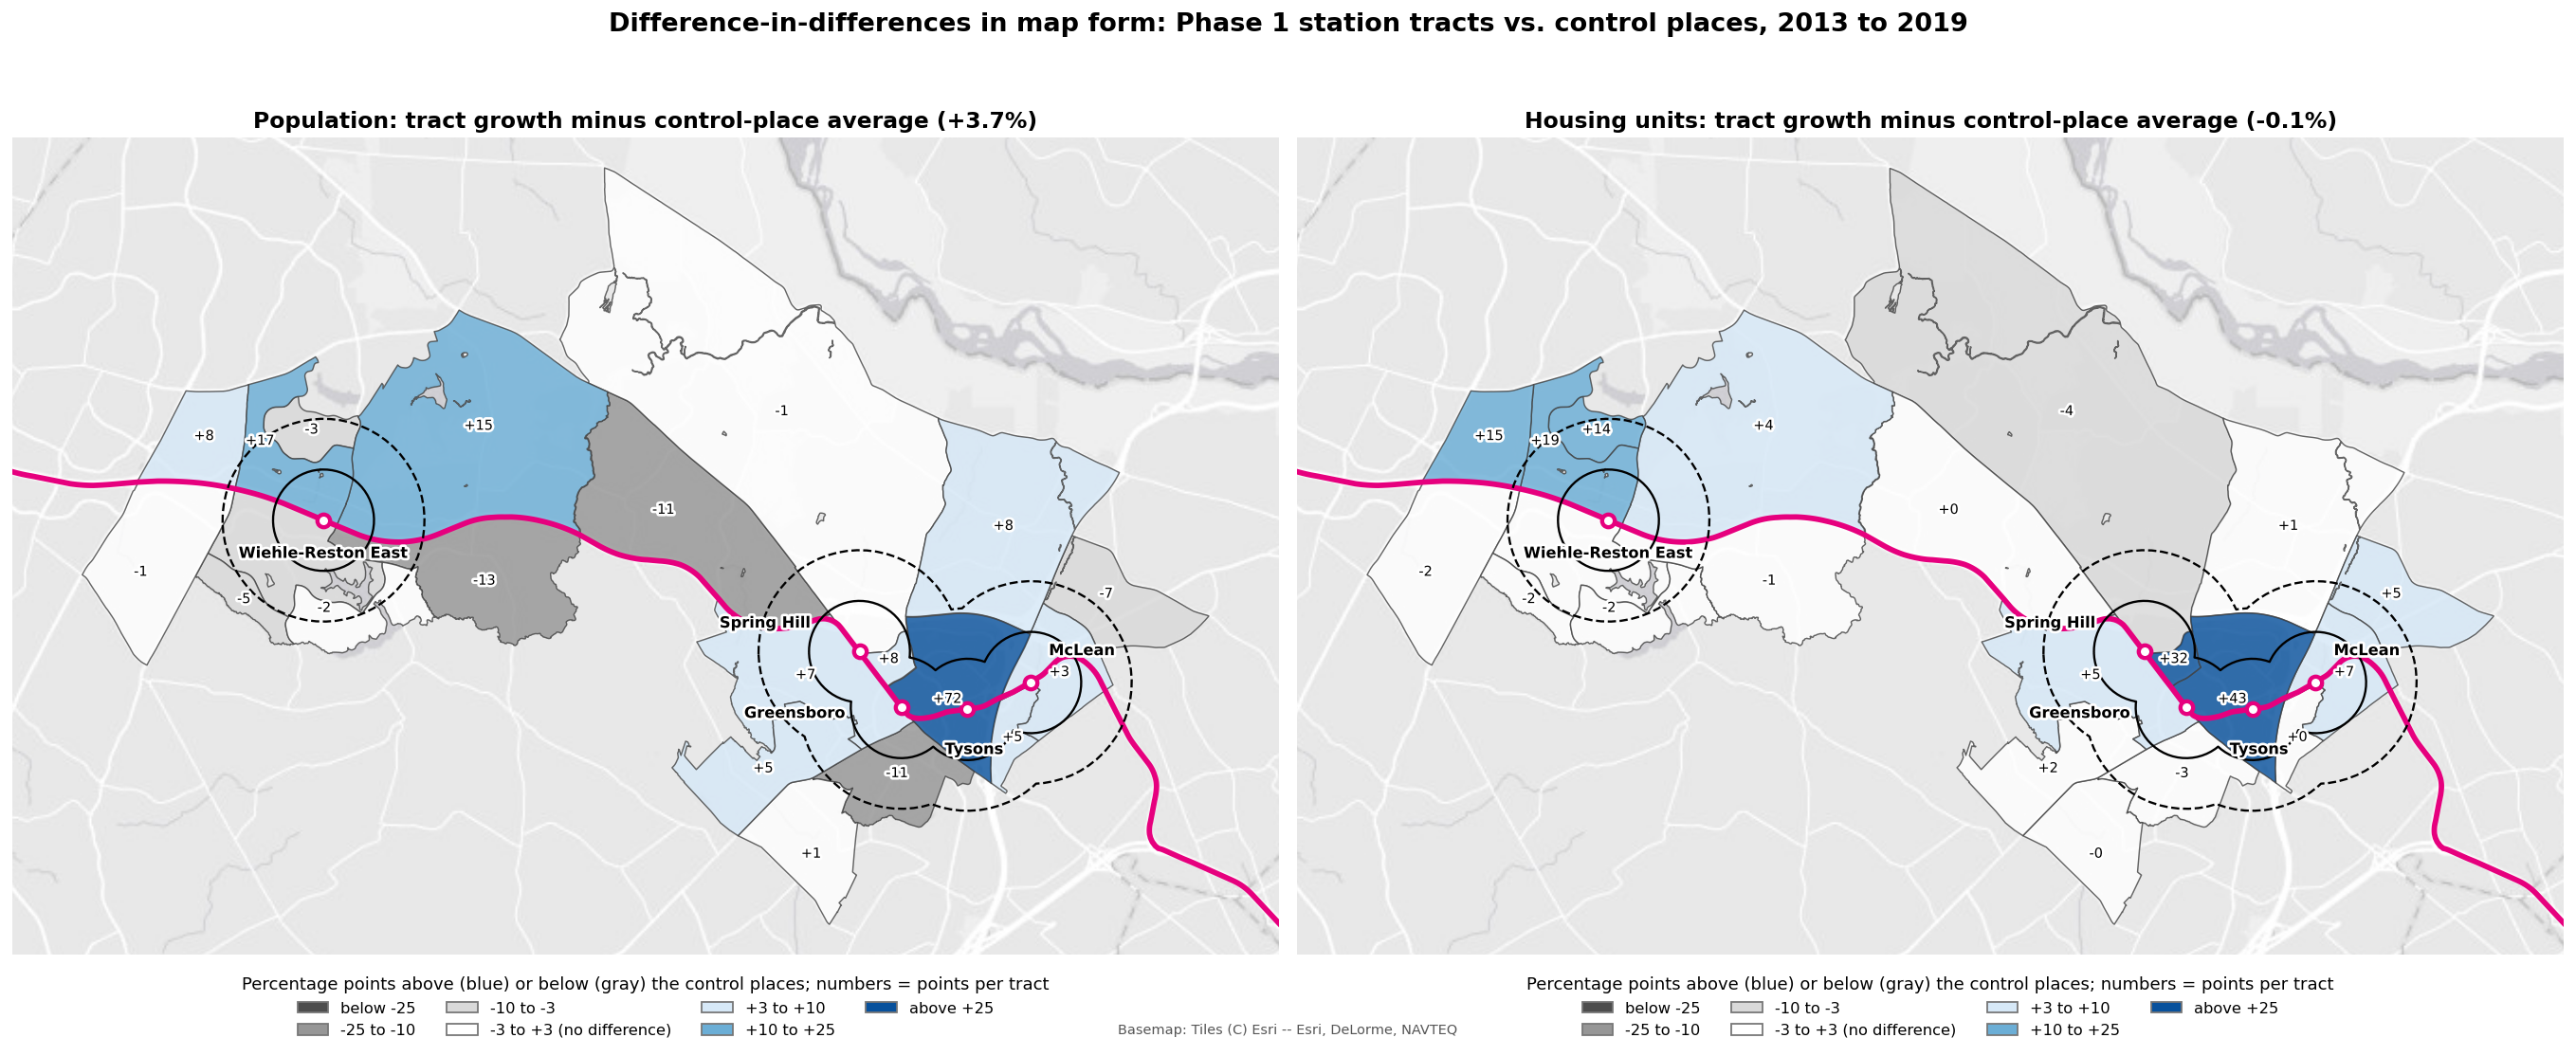

fig3_trends_and_did.png


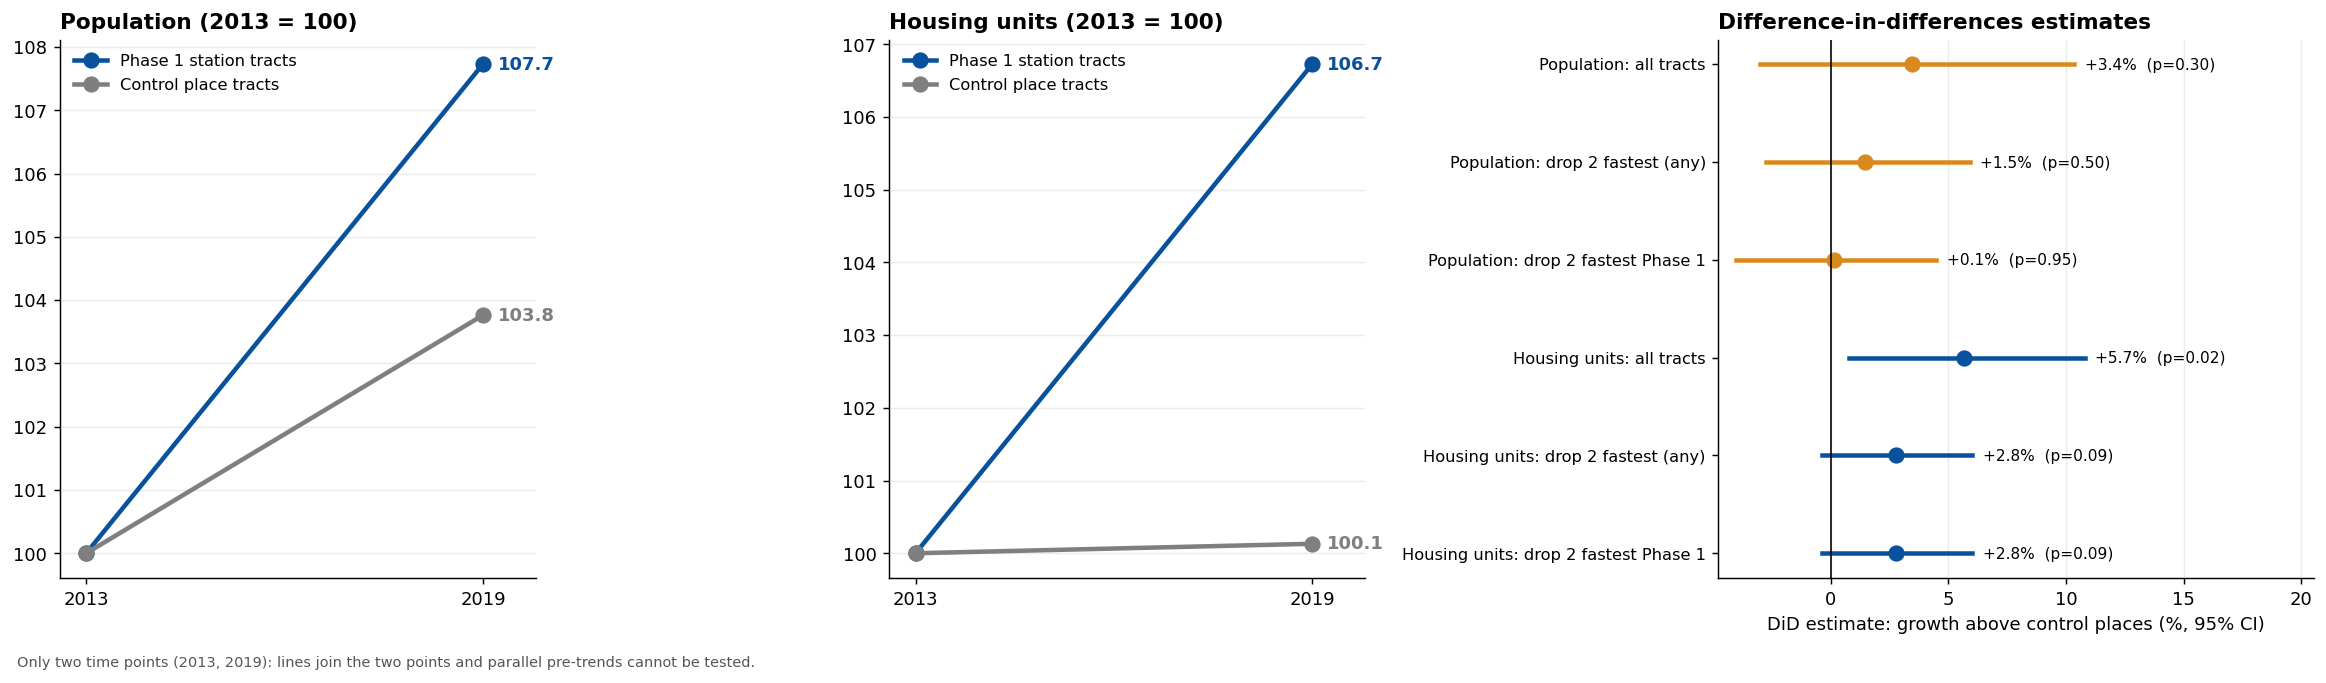

statistical_tables.png


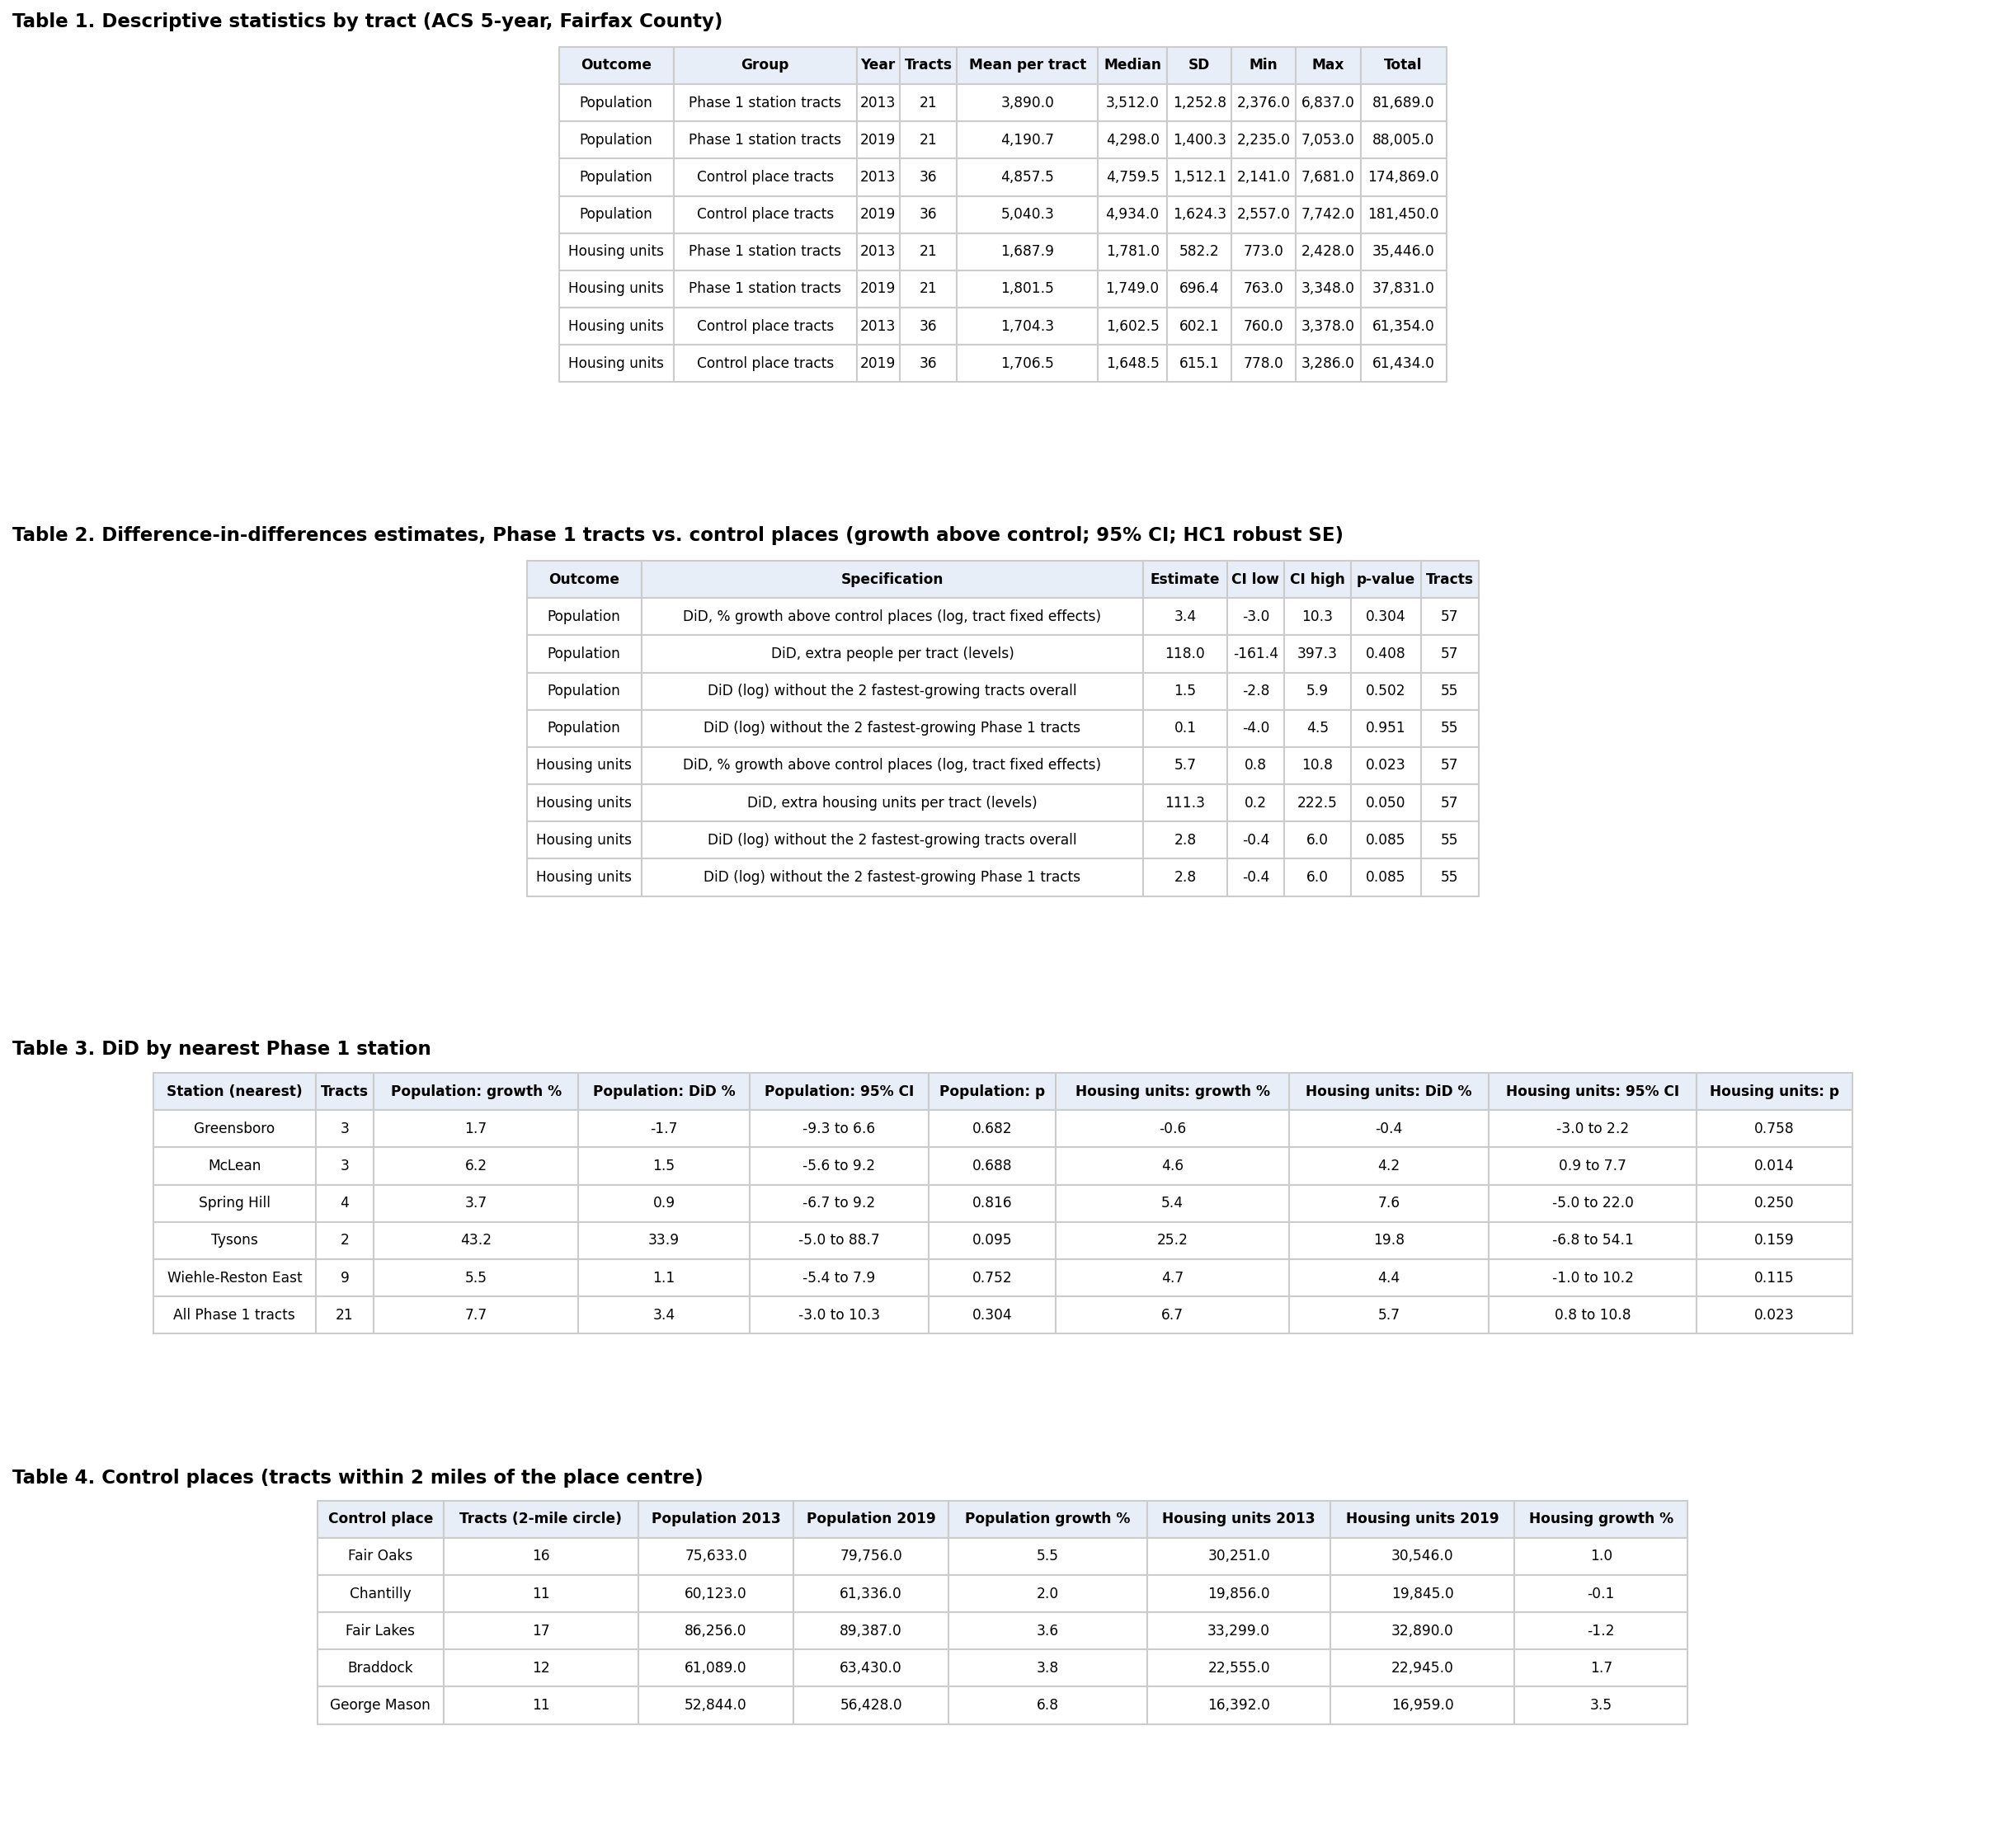

TABLE 2: difference-in-differences estimates


,Outcome,Specification,Estimate,CI low,CI high,p-value,Tracts
0,Population,"DiD, % growth above control places (log, tract...",3.440,-3.018,10.328,0.304,57
1,Population,"DiD, extra people per tract (levels)",117.956,-161.374,397.287,0.408,57
2,Population,DiD (log) without the 2 fastest-growing tracts...,1.474,-2.771,5.904,0.502,55
3,Population,DiD (log) without the 2 fastest-growing Phase ...,0.134,-4.035,4.483,0.951,55
4,Housing units,"DiD, % growth above control places (log, tract...",5.660,0.772,10.785,0.023,57
5,Housing units,"DiD, extra housing units per tract (levels)",111.349,0.240,222.459,0.050,57
6,Housing units,DiD (log) without the 2 fastest-growing tracts...,2.766,-0.379,6.010,0.085,55
7,Housing units,DiD (log) without the 2 fastest-growing Phase ...,2.766,-0.379,6.010,0.085,55


TABLE 3: by nearest station


,Station (nearest),Tracts,Population: growth %,Population: DiD %,Population: 95% CI,Population: p,Housing units: growth %,Housing units: DiD %,Housing units: 95% CI,Housing units: p
0,Greensboro,3,1.691,-1.681,-9.3 to 6.6,0.682,-0.564,-0.408,-3.0 to 2.2,0.758
1,McLean,3,6.246,1.508,-5.6 to 9.2,0.688,4.576,4.247,0.9 to 7.7,0.014
2,Spring Hill,4,3.712,0.935,-6.7 to 9.2,0.816,5.387,7.631,-5.0 to 22.0,0.250
3,Tysons,2,43.179,33.904,-5.0 to 88.7,0.095,25.175,19.826,-6.8 to 54.1,0.159
4,Wiehle-Reston East,9,5.536,1.062,-5.4 to 7.9,0.752,4.744,4.403,-1.0 to 10.2,0.115
5,All Phase 1 tracts,21,7.732,3.440,-3.0 to 10.3,0.304,6.729,5.660,0.8 to 10.8,0.023


In [ ]:
from IPython.display import Image, display
for f in ["fig1_study_area_map.png", "fig2_did_map_pop_housing.png", "fig3_trends_and_did.png", "statistical_tables.png"]:
    print(f); display(Image(filename=os.path.join(OUT_DIR, f)))
print("TABLE 2: difference-in-differences estimates"); display(tab2.round(3))
print("TABLE 3: by nearest station"); display(tab3.round(3))

## 16. Download everything (one zip)

In [ ]:
import shutil
shutil.make_archive("silver_line_population_housing_outputs", "zip", OUT_DIR)
from google.colab import files
files.download("silver_line_population_housing_outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>